# Few-Shot Learning with Prototypical Networks (Omniglot)

In [1]:
include("setup.jl")


  Activating project at `~/Documents/Egyetem/ADM/ML/few_shot_learning_prototypization`


In [2]:
using Flux
using Images
using ImageTransformations
using Downloads
using StatsBase
using Statistics
using LinearAlgebra
using Plots
using Random

Random.seed!(42)
gr()

Plots.GRBackend()

In [ ]:
const OMNIGLOT_BG_URL   = "https://raw.githubusercontent.com/brendenlake/omniglot/master/python/images_background.zip"
const OMNIGLOT_EVAL_URL = "https://raw.githubusercontent.com/brendenlake/omniglot/master/python/images_evaluation.zip"

struct OmniglotDataset
    root_dir::String
    classes::Vector{String}
    class_images::Dict{String, Vector{String}}
end

function download_and_extract(url::String, dest_zip::String, extract_to::String)
    if !isfile(dest_zip)
        Downloads.download(url, dest_zip; headers=["User-Agent" => "Mozilla/5.0"])
    end
    
    folder_name = replace(basename(dest_zip), ".zip" => "")
    full_path = joinpath(extract_to, folder_name)
    if !isdir(full_path)
        mkpath(extract_to)
        run(`unzip -q -o $dest_zip -d $extract_to`)
    end
end

function OmniglotDataset(base_dir::String = joinpath(@__DIR__, "omniglot_data"); split::Symbol = :train)
    mkpath(base_dir)
    zip_name = split == :train ? "images_background.zip" : "images_evaluation.zip"
    url = split == :train ? OMNIGLOT_BG_URL : OMNIGLOT_EVAL_URL
    
    zip_path = joinpath(base_dir, zip_name)
    extract_dir = base_dir
    folder_name = replace(zip_name, ".zip" => "")
    full_split_dir = joinpath(extract_dir, folder_name)
    
    download_and_extract(url, zip_path, extract_dir)
    
    class_images = Dict{String, Vector{String}}()
    classes = String[]
    
    alphabets = filter(d -> isdir(joinpath(full_split_dir, d)), readdir(full_split_dir))
    for alphabet in alphabets
        alpha_dir = joinpath(full_split_dir, alphabet)
        chars = filter(d -> isdir(joinpath(alpha_dir, d)), readdir(alpha_dir))
        for ch in chars
            char_dir = joinpath(alpha_dir, ch)
            imgs = [joinpath(char_dir, f) for f in readdir(char_dir) if endswith(lowercase(f), ".png")]
            if length(imgs) >= 10
                cls_id = "$alpha/$ch"
                push!(classes, cls_id)
                class_images[cls_id] = imgs
            end
        end
    end
    
    println("Loaded Omniglot $(split) split: $(length(classes)) character classes.")
    return OmniglotDataset(full_split_dir, classes, class_images)
end

train_dataset = OmniglotDataset(; split=:train)
eval_dataset  = OmniglotDataset(; split=:test)
;

Loaded Omniglot train split: 964 character classes.
Loaded Omniglot test split: 659 character classes.


In [4]:
INPUT_SIZE = (64, 64) # max (105, 105)

function preprocess_image(path::String; target_size=INPUT_SIZE)
    img = Images.load(path)
    img_resized = ImageTransformations.imresize(img, target_size)
    arr = Float32.(1.0f0 .- Gray.(img_resized))
    return reshape(arr, target_size[1], target_size[2], 1)
end

function sample_episode_batch(dataset::OmniglotDataset, n_way::Int, k_shot::Int, q_query::Int)
    selected_classes = sample(dataset.classes, n_way; replace=false)
    
    support_imgs = Array{Float32, 4}(undef, INPUT_SIZE[1], INPUT_SIZE[2], 1, n_way * k_shot)
    query_imgs   = Array{Float32, 4}(undef, INPUT_SIZE[1], INPUT_SIZE[2], 1, n_way * q_query)
    
    support_paths = Vector{String}(undef, n_way * k_shot)
    query_paths   = Vector{String}(undef, n_way * q_query)
    
    for (c_idx, c) in enumerate(selected_classes)
        all_imgs = dataset.class_images[c]
        chosen = sample(all_imgs, k_shot + q_query; replace=false)
        
        for k in 1:k_shot
            s_idx = (c_idx - 1) * k_shot + k
            support_imgs[:, :, :, s_idx] = preprocess_image(chosen[k])
            support_paths[s_idx] = chosen[k]
        end
        for q in 1:q_query
            q_idx = (c_idx - 1) * q_query + q
            query_imgs[:, :, :, q_idx] = preprocess_image(chosen[k_shot + q])
            query_paths[q_idx] = chosen[k_shot + q]
        end
    end
    
    return (
        support_imgs  = support_imgs,
        query_imgs    = query_imgs,
        support_paths = support_paths,
        query_paths   = query_paths,
        classes       = selected_classes
    )
end


sample_episode_batch (generic function with 1 method)

In [19]:
conv_block(in_c, out_c) = Chain(
    Conv((3, 3), in_c => out_c, pad=1),
    BatchNorm(out_c, relu),
    MaxPool((2, 2))
)

function build_conv_backbone(; in_channels=1, hidden_dim=64)
    return Chain(
        conv_block(in_channels, hidden_dim),
        conv_block(hidden_dim, hidden_dim),
        conv_block(hidden_dim, hidden_dim),
        conv_block(hidden_dim, hidden_dim),
        Flux.flatten
    )
end

backbone = build_conv_backbone()
println("Total parameters: $(sum(length, Flux.params(backbone)))")


Total parameters: 111936


In [6]:
function compute_prototypes(support_feats::AbstractMatrix, n_way::Int, k_shot::Int)
    D = size(support_feats, 1)
    reshaped = reshape(support_feats, D, k_shot, n_way)
    return dropdims(mean(reshaped; dims=2); dims=2) # (D, n_way)
end

function pairwise_sq_euclidean(queries::AbstractMatrix, prototypes::AbstractMatrix)
    # queries: (D, N_queries), prototypes: (D, N_way)
    q2 = sum(abs2, queries; dims=1)     # (1, N_queries)
    p2 = sum(abs2, prototypes; dims=1)  # (1, N_way)
    return max.(p2' .- 2.0f0 .* (prototypes' * queries) .+ q2, 0.0f0)
end

function proto_loss_and_acc(model, support_batch, query_batch, n_way::Int, k_shot::Int, q_query::Int)
    s_emb = model(support_batch)
    q_emb = model(query_batch)
    protos = compute_prototypes(s_emb, n_way, k_shot)
    dists  = pairwise_sq_euclidean(q_emb, protos) # (n_way, n_queries)
    
    logits = -dists
    targets = repeat(1:n_way, inner=q_query)
    target_onehot = Flux.onehotbatch(targets, 1:n_way)
    
    loss = Flux.logitcrossentropy(logits, target_onehot)
    preds = [argmin(dists[:, i]) for i in 1:size(dists, 2)]
    acc = mean(preds .== targets)
    
    return loss, acc, protos, dists, s_emb, q_emb
end


proto_loss_and_acc (generic function with 1 method)

In [20]:
function train_protonet!(model, dataset::OmniglotDataset; 
                         num_episodes::Int = 150, 
                         n_way::Int = 5, 
                         k_shot::Int = 1, 
                         q_query::Int = 5, 
                         lr::Float64 = 1e-3)
    Flux.trainmode!(model)
    opt = Flux.setup(Flux.Adam(Float32(lr)), model)
    
    train_losses = Float64[]
    train_accs   = Float64[]
    
    println("Training Prototypical Network on CPU ($num_episodes episodes, $n_way-way $k_shot-shot)")
    
    for ep in 1:num_episodes
        ep_data = sample_episode_batch(dataset, n_way, k_shot, q_query)
        
        loss_val = 0.0f0
        acc_val  = 0.0f0
        
        grads = Flux.gradient(model) do m
            loss, acc, _, _, _, _ = proto_loss_and_acc(m, ep_data.support_imgs, ep_data.query_imgs, n_way, k_shot, q_query)
            loss_val = loss
            acc_val  = acc
            return loss
        end
        
        Flux.update!(opt, model, grads[1])
        
        push!(train_losses, Float64(loss_val))
        push!(train_accs, Float64(acc_val))
        
        if ep % 10 == 0 || ep == num_episodes
            running_loss = mean(train_losses[max(1, ep - 19):ep])
            running_acc  = mean(train_accs[max(1, ep - 19):ep]) * 100
            print("\rEpisode $(lpad(ep, 4))/$(num_episodes) | Loss: $(round(running_loss, digits=4)) | Acc: $(round(running_acc, digits=2))%")
        end
    end

    return train_losses, train_accs
end

train_losses, train_accs = train_protonet!(backbone, train_dataset; num_episodes=500, n_way=5, k_shot=1, q_query=5, lr=1e-3)
;


Training Prototypical Network on CPU (500 episodes, 5-way 1-shot)
Episode  500/500 | Loss: 0.8398 | Acc: 94.0%%

In [21]:
function evaluate_protonet(model, dataset::OmniglotDataset; 
                           num_episodes::Int = 100, 
                           n_way::Int = 5, 
                           k_shot::Int = 5, 
                           q_query::Int = 5)
    Flux.testmode!(model)
    accuracies = Float64[]
    
    for ep in 1:num_episodes
        ep_data = sample_episode_batch(dataset, n_way, k_shot, q_query)
        _, acc, _, _, _, _ = proto_loss_and_acc(model, ep_data.support_imgs, ep_data.query_imgs, n_way, k_shot, q_query)
        push!(accuracies, acc)
    end
    
    return mean(accuracies) * 100
end

evaluate_protonet(backbone, eval_dataset; num_episodes=80, n_way=5, k_shot=5, q_query=5)

84.90000000000002

Sample Episode Accuracy: 76.0%


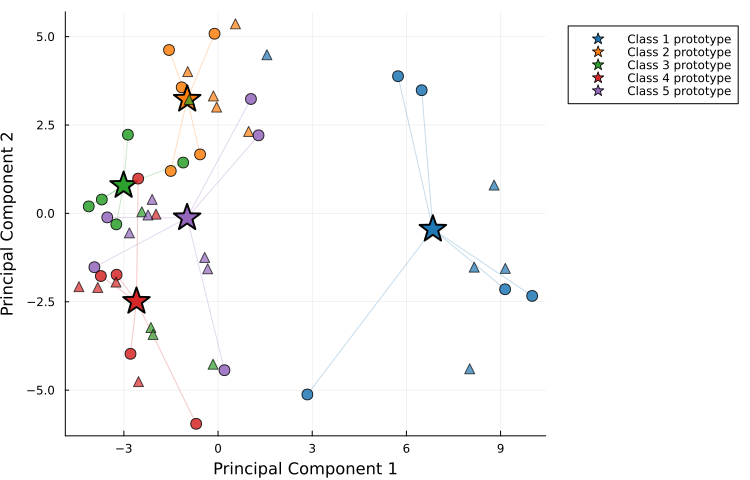

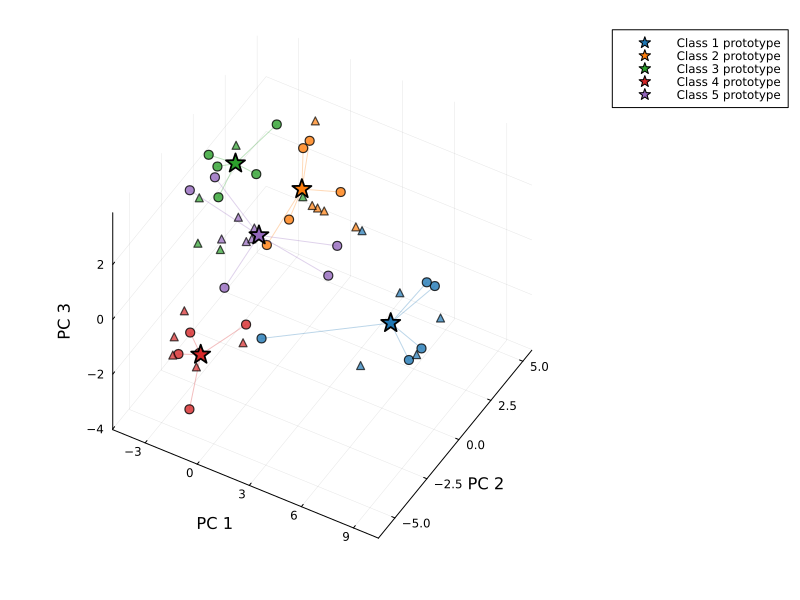

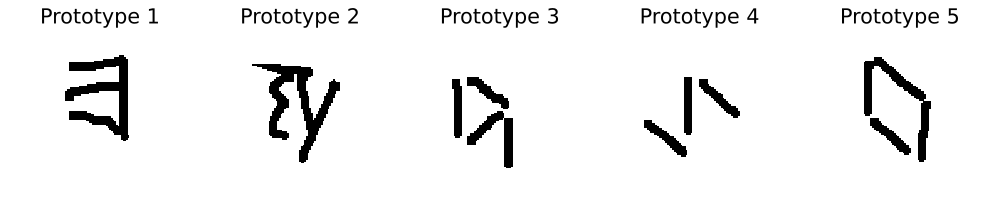

In [23]:
n_vis_way = 5
k_vis_shot = 5
q_vis_query = 5

Flux.testmode!(backbone)
vis_ep = sample_episode_batch(eval_dataset, n_vis_way, k_vis_shot, q_vis_query)
loss_v, acc_v, protos, dists, s_emb, q_emb = proto_loss_and_acc(
    backbone, vis_ep.support_imgs, vis_ep.query_imgs, n_vis_way, k_vis_shot, q_vis_query
)

println("Sample Episode Accuracy: $(round(acc_v * 100, digits=2))%")

function plot_prototypes_pca(s_emb, q_emb, protos, n_way, k_shot, q_query, class_names)
    all_vectors = hcat(s_emb, q_emb, protos)
    μ = mean(all_vectors; dims=2)
    U = svd(all_vectors .- μ).U[:, 1:2]
    
    s_2d = U' * (s_emb .- μ)
    q_2d = U' * (q_emb .- μ)
    p_2d = U' * (protos .- μ)
    
    p = plot(xlabel="Principal Component 1", ylabel="Principal Component 2", size=(750, 480), legend=:outertopright)
             
    colors = palette(:tab10)
    for c in 1:n_way
        s_idx = ((c - 1) * k_shot + 1):(c * k_shot)
        q_idx = ((c - 1) * q_query + 1):(c * q_query)
        
        # Connect support points to prototype
        for i in s_idx
            plot!(p, [s_2d[1, i], p_2d[1, c]], [s_2d[2, i], p_2d[2, c]],
                  color=colors[c], alpha=0.25, lw=1, label="")
        end
        
        # Support points
        scatter!(p, s_2d[1, s_idx], s_2d[2, s_idx], color=colors[c], marker=:circle, markersize=6, alpha=0.85, label="")
                 
        # Query points
        scatter!(p, q_2d[1, q_idx], q_2d[2, q_idx], color=colors[c], marker=:utriangle, markersize=5, alpha=0.7, label="")
                 
        # Prototype Centroid
        scatter!(p, [p_2d[1, c]], [p_2d[2, c]],
                 label="Class $c prototype", color=colors[c],
                 marker=:star5, markersize=14, markerstrokecolor=:black, markerstrokewidth=2)
    end
    return p
end

function plot_prototypes_pca_3d(s_emb, q_emb, protos, n_way, k_shot, q_query, class_names)
    all_vectors = hcat(s_emb, q_emb, protos)
    μ = mean(all_vectors; dims=2)
    U = svd(all_vectors .- μ).U[:, 1:3]
    
    s_3d = U' * (s_emb .- μ)
    q_3d = U' * (q_emb .- μ)
    p_3d = U' * (protos .- μ)
    
    p = plot(
        xlabel="PC 1", ylabel="PC 2", zlabel="PC 3",
        size=(800, 600), 
        legend=:outertopright,
        camera=(30, 45)
    )
             
    colors = palette(:tab10)
    for c in 1:n_way
        s_idx = ((c - 1) * k_shot + 1):(c * k_shot)
        q_idx = ((c - 1) * q_query + 1):(c * q_query)
        
        c_label = replace(split(class_names[c], "/")[end], "_" => " ")
        for i in s_idx
            plot!(p, 
                  [s_3d[1, i], p_3d[1, c]], 
                  [s_3d[2, i], p_3d[2, c]], 
                  [s_3d[3, i], p_3d[3, c]],
                  color=colors[c], alpha=0.3, lw=1, label="")
        end
        
        # Support points
        scatter!(p, 
                 s_3d[1, s_idx], s_3d[2, s_idx], s_3d[3, s_idx], 
                 color=colors[c], marker=:circle, markersize=5, alpha=0.8, label="")
                 
        # Query points
        scatter!(p, 
                 q_3d[1, q_idx], q_3d[2, q_idx], q_3d[3, q_idx], 
                 color=colors[c], marker=:utriangle, markersize=4, alpha=0.7, label="")
                 
        # Prototype Centroid
        scatter!(p, 
                 [p_3d[1, c]], [p_3d[2, c]], [p_3d[3, c]],
                 label="Class $c prototype", color=colors[c],
                 marker=:star5, markersize=10, markerstrokecolor=:black, markerstrokewidth=1.5)
    end
    
    return p
end

function plot_prototype_exemplars(vis_ep, protos, s_emb, n_way, k_shot)
    plots = []
    
    for c in 1:n_way
        proto_c = protos[:, c]
        s_idx = ((c - 1) * k_shot + 1):(c * k_shot)
        
        # Find closest support sample to the prototype
        dists_to_proto = [norm(s_emb[:, i] - proto_c) for i in s_idx]
        best_local_idx = argmin(dists_to_proto)
        best_img_path = vis_ep.support_paths[s_idx[best_local_idx]]
        
        img = Images.load(best_img_path)
        c_name = replace(split(vis_ep.classes[c], "/")[end], "_" => " ")
        
        p = plot(img, title="Prototype $c\n($c_name)", axis=false, ticks=false)
        push!(plots, p)
    end
    
    return plot(plots..., layout=(1, n_way), size=(200 * n_way, 220))
end

p_pca = plot_prototypes_pca(s_emb, q_emb, protos, n_vis_way, k_vis_shot, q_vis_query, vis_ep.classes)
display(p_pca)

p_pca = plot_prototypes_pca_3d(s_emb, q_emb, protos, n_vis_way, k_vis_shot, q_vis_query, vis_ep.classes)
display(p_pca)

p_protos = plot_prototype_exemplars(vis_ep, protos, s_emb, n_vis_way, k_vis_shot)
display(p_protos)
